In [1]:
import pandas as pd
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.model_selection import StratifiedKFold
from sklearn.metrics import accuracy_score, confusion_matrix, ConfusionMatrixDisplay
from torch.utils.data import DataLoader, TensorDataset
from tqdm import tqdm
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
import time
import seaborn as sns
import plotly.express as px
pd.set_option('display.max_rows', None)  # Show all rows
pd.set_option('display.max_columns', None) # Show all columns
pd.set_option('display.width', 1000) # Adjust display width

In [2]:
df = pd.read_csv('CIC-BCCC-NRC-TabularIoTAttacks-2024-balanced_dataset.csv')

In [3]:
df.head()

,Protocol,Flow Duration,Total Fwd Packet,Total Bwd packets,Total Length of Fwd Packet,Total Length of Bwd Packet,Fwd Packet Length Max,Fwd Packet Length Min,Fwd Packet Length Mean,Fwd Packet Length Std,Bwd Packet Length Max,Bwd Packet Length Min,Bwd Packet Length Mean,Bwd Packet Length Std,Flow Bytes/s,Flow Packets/s,Flow IAT Mean,Flow IAT Std,Flow IAT Max,Flow IAT Min,Fwd IAT Total,Fwd IAT Mean,Fwd IAT Std,Fwd IAT Max,Fwd IAT Min,Bwd IAT Total,Bwd IAT Mean,Bwd IAT Std,Bwd IAT Max,Bwd IAT Min,Fwd PSH Flags,Bwd PSH Flags,Fwd URG Flags,Bwd URG Flags,Fwd Header Length,Bwd Header Length,Fwd Packets/s,Bwd Packets/s,Packet Length Min,Packet Length Max,Packet Length Mean,Packet Length Std,Packet Length Variance,FIN Flag Count,SYN Flag Count,RST Flag Count,PSH Flag Count,ACK Flag Count,URG Flag Count,CWR Flag Count,ECE Flag Count,Down/Up Ratio,Average Packet Size,Fwd Segment Size Avg,Bwd Segment Size Avg,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,Bwd Bytes/Bulk Avg,Bwd Packet/Bulk Avg,Bwd Bulk Rate Avg,Subflow Fwd Packets,Subflow Fwd Bytes,Subflow Bwd Packets,Subflow Bwd Bytes,FWD Init Win Bytes,Bwd Init Win Bytes,Fwd Act Data Pkts,Fwd Seg Size Min,Active Mean,Active Std,Active Max,Active Min,Idle Mean,Idle Std,Idle Max,Idle Min,Label,Attack_type,Attack
0,6,4581649,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.654786,2290824.5,2.905022e+06,4344985.0,236664.0,4344985.0,4344985.0,0.0,4344985.0,4344985.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.436524,0.218262,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
1,6,300972,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.645136,300972.0,0.000000e+00,300972.0,300972.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,20,20,3.322568,3.322568,0.0,0.0,0.0,0.0,0.0,0,0,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
2,6,7462882,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.401989,3731441.0,4.894292e+06,7192228.0,270654.0,7192228.0,7192228.0,0.0,7192228.0,7192228.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.267993,0.133996,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,7192228.0,0.0,7192228.0,7192228.0,1,DDoS,ACK Flood
3,6,304278,1,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,6.572937,304278.0,0.000000e+00,304278.0,304278.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,20,20,3.286468,3.286468,0.0,0.0,0.0,0.0,0.0,0,0,1,0,1,0,0,0,1.0,0.0,0.0,0.0,0,0,0,0,0,0,0,0,0,0,512,0,0,20,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1,DDoS,ACK Flood
4,6,9177775,2,1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.326877,4588887.5,6.205263e+06,8976671.0,201104.0,8976671.0,8976671.0,0.0,8976671.0,8976671.0,0.0,0.0,0.0,0.0,0.0,0,0,0,0,40,20,0.217918,0.108959,0.0,0.0,0.0,0.0,0.0,0,0,1,0,2,0,0,0,0.0,0.0,0.0,0.0,0,0,0,0,0,0,2,0,1,0,512,0,0,20,0.0,0.0,0.0,0.0,8976671.0,0.0,8976671.0,8976671.0,1,DDoS,ACK Flood


In [4]:
df.duplicated().sum()

0

In [5]:
df.isnull().any().any()

False

In [6]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [7]:
df.shape

(1076588, 80)

In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1076588 entries, 0 to 1076587
Data columns (total 80 columns):
 #   Column                      Non-Null Count    Dtype  
---  ------                      --------------    -----  
 0   Protocol                    1076588 non-null  int64  
 1   Flow Duration               1076588 non-null  int64  
 2   Total Fwd Packet            1076588 non-null  int64  
 3   Total Bwd packets           1076588 non-null  int64  
 4   Total Length of Fwd Packet  1076588 non-null  float64
 5   Total Length of Bwd Packet  1076588 non-null  float64
 6   Fwd Packet Length Max       1076588 non-null  float64
 7   Fwd Packet Length Min       1076588 non-null  float64
 8   Fwd Packet Length Mean      1076588 non-null  float64
 9   Fwd Packet Length Std       1076588 non-null  float64
 10  Bwd Packet Length Max       1076588 non-null  float64
 11  Bwd Packet Length Min       1076588 non-null  float64
 12  Bwd Packet Length Mean      1076588 non-null  float64
 1

In [9]:
df = df.drop(['Attack_type', 'Attack'], axis=1)

In [10]:
df.isnull().sum()

Protocol                      0
Flow Duration                 0
Total Fwd Packet              0
Total Bwd packets             0
Total Length of Fwd Packet    0
Total Length of Bwd Packet    0
Fwd Packet Length Max         0
Fwd Packet Length Min         0
Fwd Packet Length Mean        0
Fwd Packet Length Std         0
Bwd Packet Length Max         0
Bwd Packet Length Min         0
Bwd Packet Length Mean        0
Bwd Packet Length Std         0
Flow Bytes/s                  0
Flow Packets/s                0
Flow IAT Mean                 0
Flow IAT Std                  0
Flow IAT Max                  0
Flow IAT Min                  0
Fwd IAT Total                 0
Fwd IAT Mean                  0
Fwd IAT Std                   0
Fwd IAT Max                   0
Fwd IAT Min                   0
Bwd IAT Total                 0
Bwd IAT Mean                  0
Bwd IAT Std                   0
Bwd IAT Max                   0
Bwd IAT Min                   0
Fwd PSH Flags                 0
Bwd PSH 

In [11]:
df['Label'].unique()

array([1, 0], dtype=int64)

<h2>Feature Selection </h2>

In [12]:
df.shape

(1076588, 78)

In [13]:
df.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Bwd PSH Flags', 'Fwd URG Flags', 'Bwd URG Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count',
       

C:\ProgramData\anaconda3\Lib\site-packages\seaborn\matrix.py:260: FutureWarning: Format strings passed to MaskedConstant are ignored, but in future may error or produce different behavior
  annotation = ("{:" + self.fmt + "}").format(val)


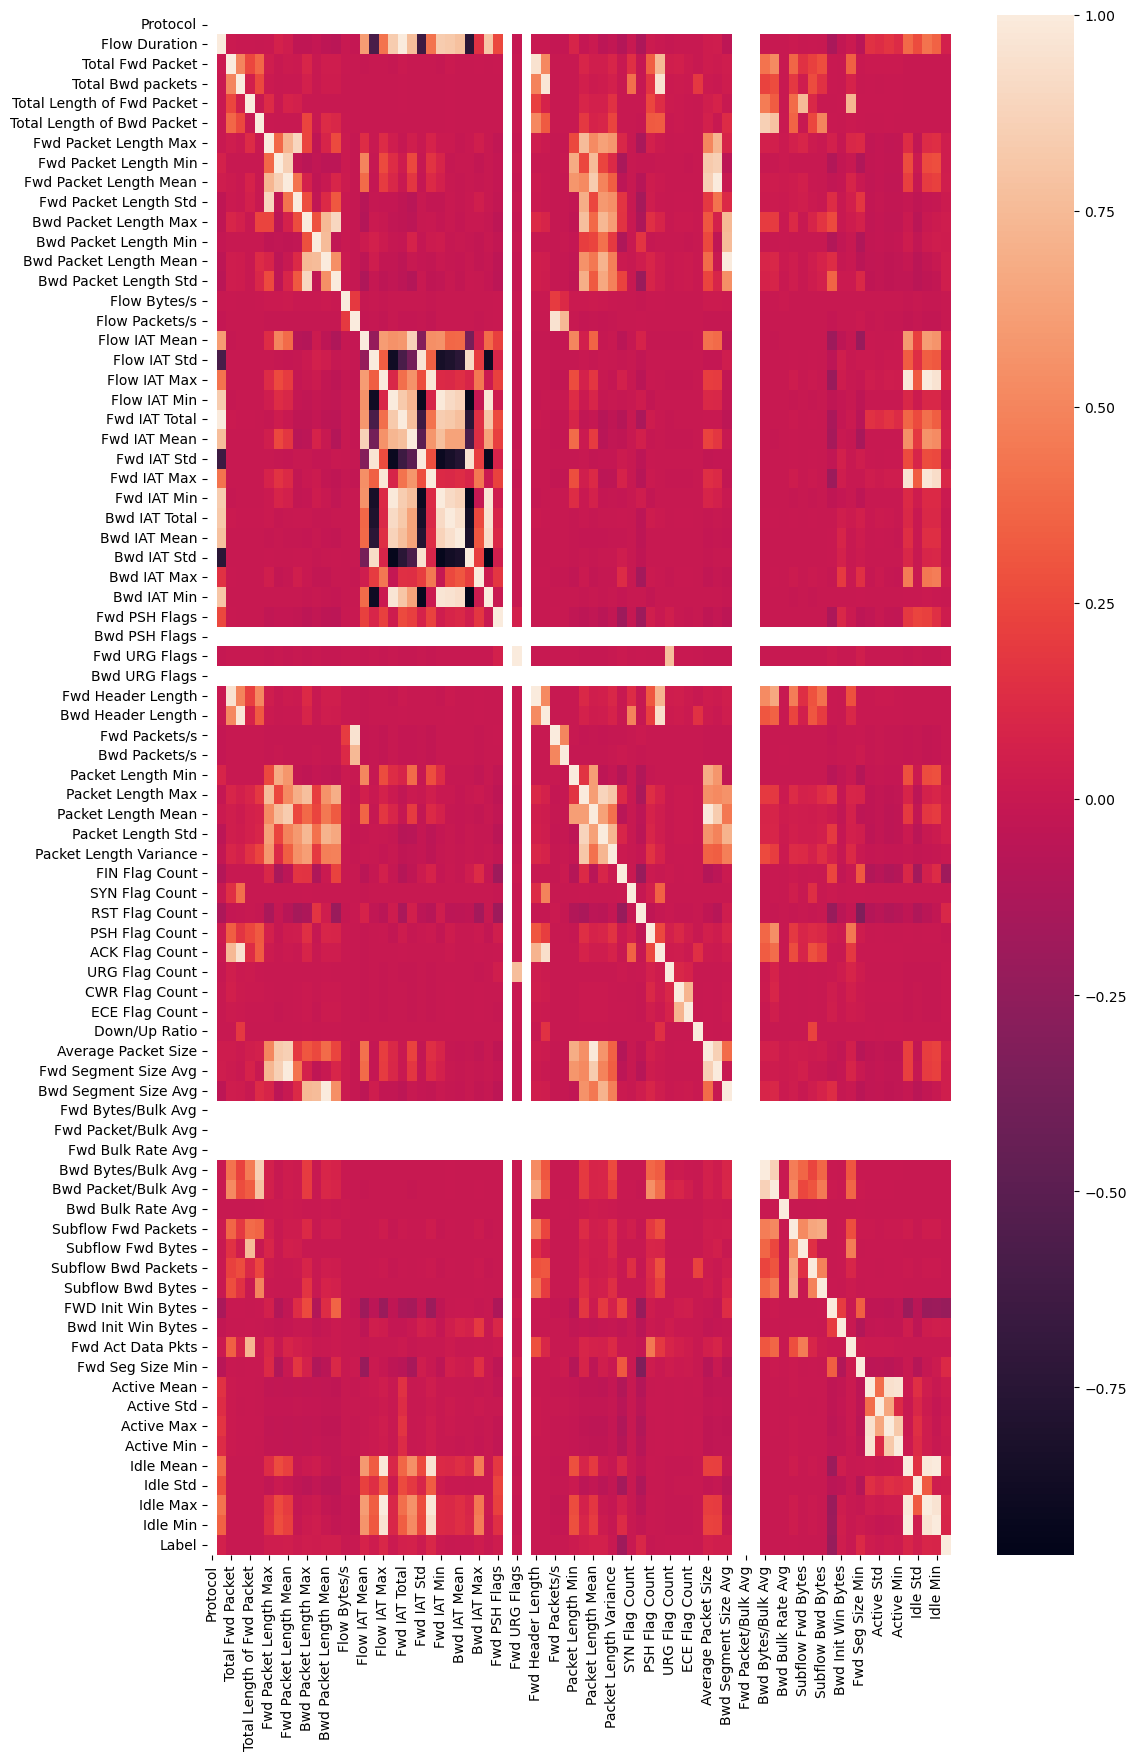

In [10]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize = (12, 20))
sns.heatmap(df.corr(), annot=True)
plt.show()

<h3>Mutual Information</h3>

In [16]:
from sklearn.feature_selection import mutual_info_classif
# Separate features and target
X = df.drop(columns=['Label'])
y = df['Label']
# Calculate mutual information

mi_scores = mutual_info_classif(X, y, discrete_features='auto', random_state=0)

# Create a DataFrame to show results
mi_df = pd.DataFrame({'Feature': X.columns, 'MI Score': mi_scores})
mi_df = mi_df.sort_values(by='MI Score', ascending=False).reset_index(drop=True)
print("Top Features by Mutual Information:")
print(mi_df)

Top Features by Mutual Information:
                       Feature  MI Score
0                     Protocol  0.201604
1            Packet Length Std  0.107078
2       Packet Length Variance  0.106957
3        Fwd Packet Length Std  0.103955
4             Fwd Seg Size Min  0.099049
5           Bwd Bytes/Bulk Avg  0.098510
6           FWD Init Win Bytes  0.098410
7            Bwd Header Length  0.097783
8            Fwd Header Length  0.097767
9           Packet Length Mean  0.097530
10        Fwd Segment Size Avg  0.096279
11      Fwd Packet Length Mean  0.096202
12         Average Packet Size  0.095659
13               Fwd IAT Total  0.092982
14                Fwd IAT Mean  0.091230
15  Total Length of Fwd Packet  0.091228
16                 Bwd IAT Max  0.085713
17                 Fwd IAT Max  0.083950
18                Flow IAT Std  0.083608
19               Fwd Packets/s  0.083533
20                 Fwd IAT Std  0.082533
21               Bwd IAT Total  0.081769
22           Packet L

In [17]:
top_features = mi_df.head(78)['Feature'].tolist()
print("\n Best 78 Features:")
print(top_features)


 Best 80 Features:
['Protocol', 'Packet Length Std', 'Packet Length Variance', 'Fwd Packet Length Std', 'Fwd Seg Size Min', 'Bwd Bytes/Bulk Avg', 'FWD Init Win Bytes', 'Bwd Header Length', 'Fwd Header Length', 'Packet Length Mean', 'Fwd Segment Size Avg', 'Fwd Packet Length Mean', 'Average Packet Size', 'Fwd IAT Total', 'Fwd IAT Mean', 'Total Length of Fwd Packet', 'Bwd IAT Max', 'Fwd IAT Max', 'Flow IAT Std', 'Fwd Packets/s', 'Fwd IAT Std', 'Bwd IAT Total', 'Packet Length Max', 'Flow IAT Mean', 'Flow Packets/s', 'Fwd Packet Length Max', 'Bwd IAT Mean', 'Flow Duration', 'Bwd Packets/s', 'Bwd Init Win Bytes', 'Bwd Bulk Rate Avg', 'Flow IAT Min', 'Flow IAT Max', 'Bwd IAT Std', 'Fwd Act Data Pkts', 'Bwd Packet Length Std', 'Bwd IAT Min', 'Bwd Segment Size Avg', 'Bwd Packet Length Mean', 'Fwd IAT Min', 'FIN Flag Count', 'Bwd Packet/Bulk Avg', 'Flow Bytes/s', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'Total Bwd packets', 'Bwd Packet Length Max', 'Total Length of Bwd Packet', 'T

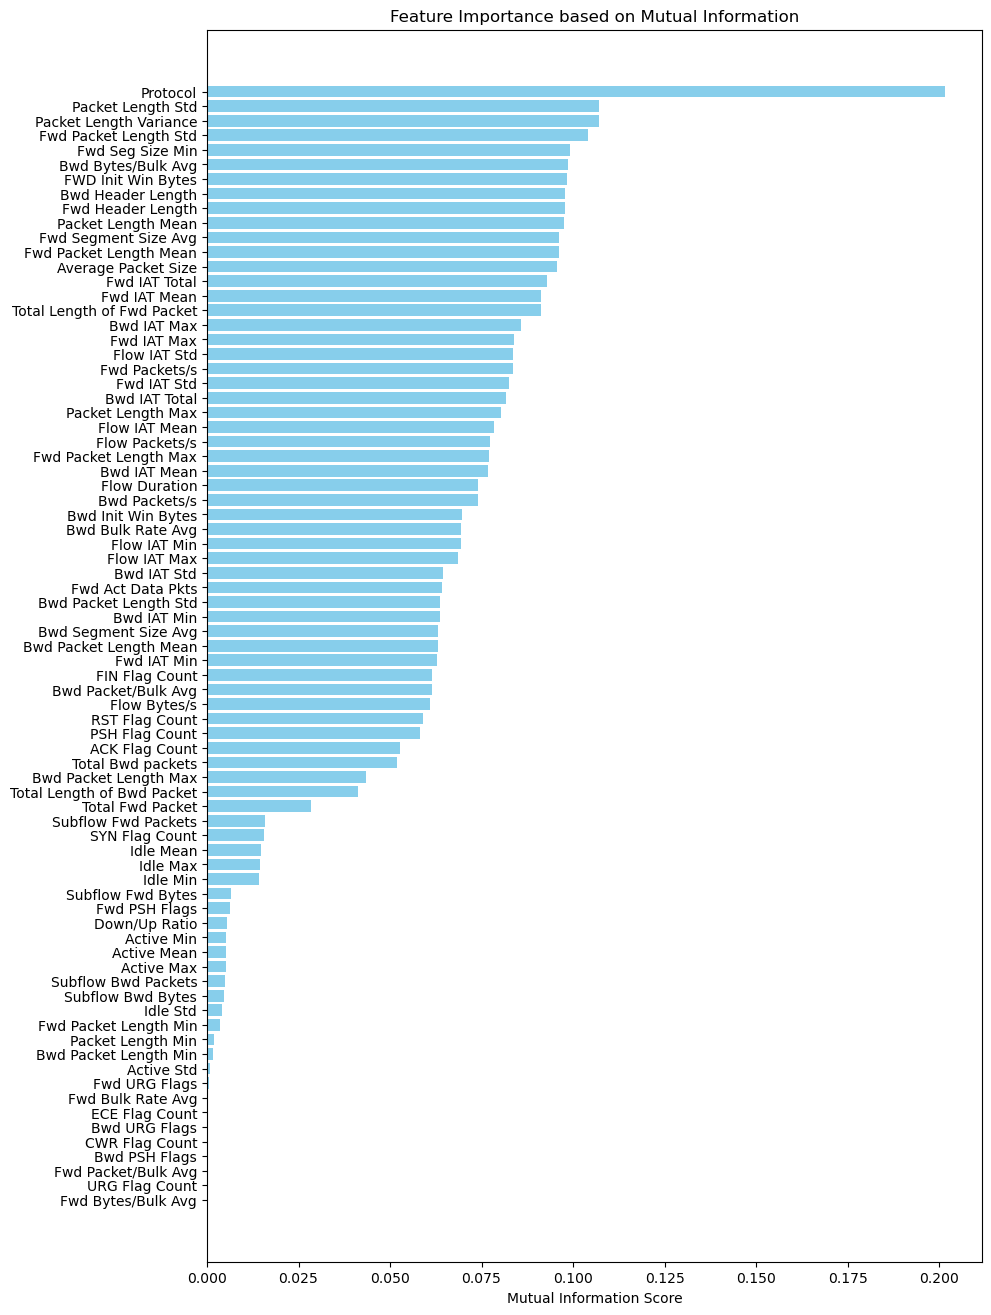

In [20]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 16))
plt.barh(mi_df['Feature'], mi_df['MI Score'], color='skyblue')
plt.xlabel("Mutual Information Score")
plt.title("Feature Importance based on Mutual Information")
plt.gca().invert_yaxis()
plt.show()

<h3>Wrapper Method: RFE</h3>

In [21]:
from sklearn.feature_selection import RFE
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(max_iter=200)
selector = RFE(model, n_features_to_select=80)
X_new = selector.fit_transform(X,y)
print("Selected features:", selector.support_)
print("Ranking of features:", selector.ranking_)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\linear_model\_logistic.py:458: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. of ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Selected features: [ True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True  True  True  True  True  True  True  True
  True  True  True  True  True]
Ranking of features: [1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1 1
 1 1 1]


<h3>Decision Tree / Random Forest</h3>

Feature importances:
Feature 0 (Protocol): 0.0000
Feature 1 (Flow Duration): 0.0186
Feature 2 (Total Fwd Packet): 0.0199
Feature 3 (Total Bwd packets): 0.0078
Feature 4 (Total Length of Fwd Packet): 0.0200
Feature 5 (Total Length of Bwd Packet): 0.0057
Feature 6 (Fwd Packet Length Max): 0.0090
Feature 7 (Fwd Packet Length Min): 0.0003
Feature 8 (Fwd Packet Length Mean): 0.0148
Feature 9 (Fwd Packet Length Std): 0.0107
Feature 10 (Bwd Packet Length Max): 0.0050
Feature 11 (Bwd Packet Length Min): 0.0004
Feature 12 (Bwd Packet Length Mean): 0.0105
Feature 13 (Bwd Packet Length Std): 0.0050
Feature 14 (Flow Bytes/s): 0.0199
Feature 15 (Flow Packets/s): 0.0215
Feature 16 (Flow IAT Mean): 0.0289
Feature 17 (Flow IAT Std): 0.0222
Feature 18 (Flow IAT Max): 0.0200
Feature 19 (Flow IAT Min): 0.0171
Feature 20 (Fwd IAT Total): 0.0282
Feature 21 (Fwd IAT Mean): 0.0145
Feature 22 (Fwd IAT Std): 0.0178
Feature 23 (Fwd IAT Max): 0.0238
Feature 24 (Fwd IAT Min): 0.0143
Feature 25 (Bwd IAT Total): 0.

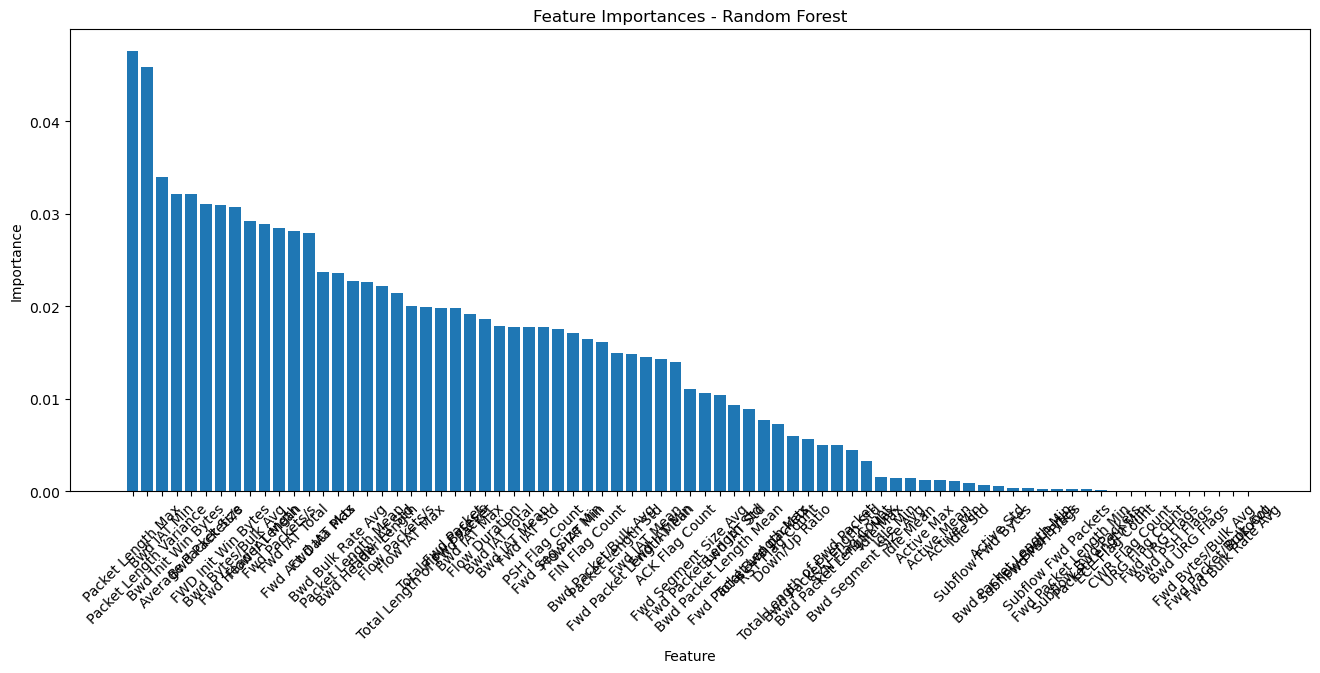

In [22]:
from sklearn.ensemble import RandomForestClassifier
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X, y)
importances = model.feature_importances_
indices = np.argsort(importances)[::-1]
print("Feature importances:")
for i in range(X.shape[1]):
    print(f"Feature {i} ({df.columns[i]}): {importances[i]:.4f}")
plt.figure(figsize=(16, 6))
plt.title('Feature Importances - Random Forest')
plt.bar(range(X.shape[1]), importances[indices], align='center')
plt.xticks(range(X.shape[1]), np.array(df.columns)[indices], rotation=45)
plt.xlabel('Feature')
plt.ylabel('Importance')
plt.show()

In [14]:
df = df.drop(['Bwd PSH Flags', 'Bwd URG Flags', 'Fwd Bytes/Bulk Avg', 
              'Fwd Packet/Bulk Avg', 'Fwd Bulk Rate Avg', 'URG Flag Count', 'CWR Flag Count', 'Fwd URG Flags'], axis=1)

<h2>Outliers</h2>

In [15]:
df2 = df.copy()

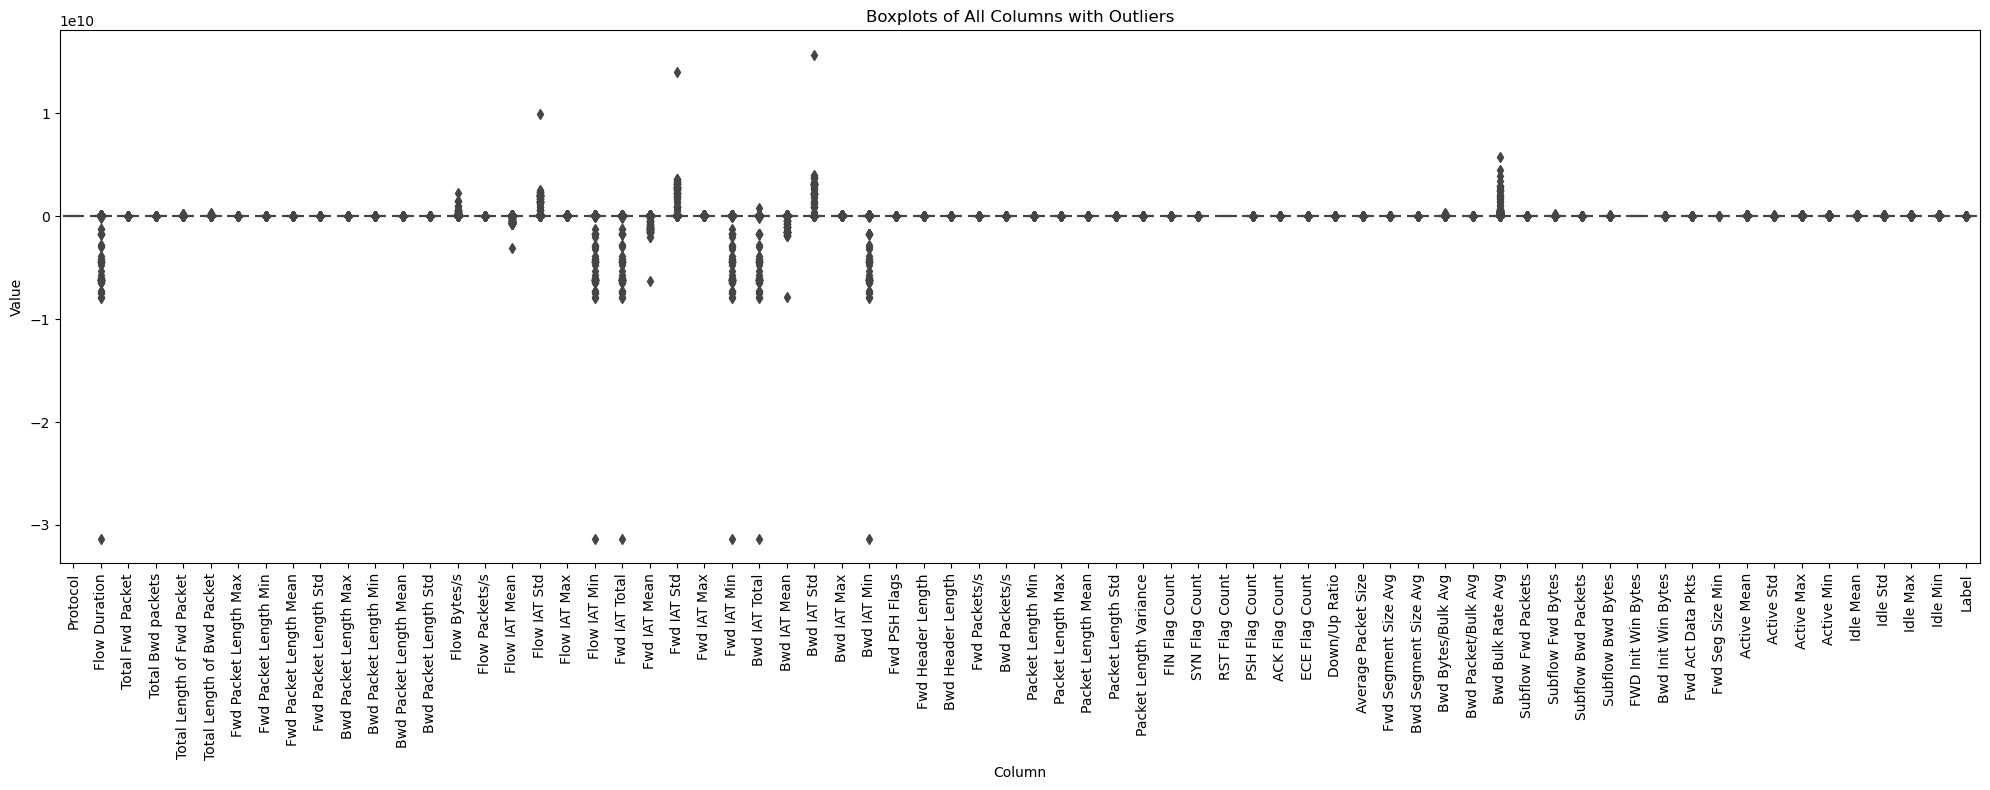

In [16]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.savefig("Graphs/outliers.pdf")   # <-- save as PDF
plt.show()

In [17]:
outliers_per_column = {}
for col in df2.select_dtypes(include=np.number).columns:
    Q1 = df2[col].quantile(0.25)
    Q3 = df2[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    outliers = df2[(df2[col] < lower) | (df2[col] > upper)]
    outliers_per_column[col] = len(outliers)

In [18]:
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 187276,
 'Total Fwd Packet': 101474,
 'Total Bwd packets': 82392,
 'Total Length of Fwd Packet': 218708,
 'Total Length of Bwd Packet': 235451,
 'Fwd Packet Length Max': 211078,
 'Fwd Packet Length Min': 69940,
 'Fwd Packet Length Mean': 215848,
 'Fwd Packet Length Std': 186950,
 'Bwd Packet Length Max': 234713,
 'Bwd Packet Length Min': 40220,
 'Bwd Packet Length Mean': 236526,
 'Bwd Packet Length Std': 201638,
 'Flow Bytes/s': 247746,
 'Flow Packets/s': 141990,
 'Flow IAT Mean': 180270,
 'Flow IAT Std': 212439,
 'Flow IAT Max': 160066,
 'Flow IAT Min': 226362,
 'Fwd IAT Total': 195049,
 'Fwd IAT Mean': 178881,
 'Fwd IAT Std': 225292,
 'Fwd IAT Max': 162928,
 'Fwd IAT Min': 211025,
 'Bwd IAT Total': 236209,
 'Bwd IAT Mean': 221740,
 'Bwd IAT Std': 241932,
 'Bwd IAT Max': 222593,
 'Bwd IAT Min': 239503,
 'Fwd PSH Flags': 95361,
 'Fwd Header Length': 91161,
 'Bwd Header Length': 71362,
 'Fwd Packets/s': 134854,
 'Bwd Packets/s': 176220,
 'Packet Length 

In [19]:
outliers_per_column.pop("Label")
outliers_per_column

{'Protocol': 0,
 'Flow Duration': 187276,
 'Total Fwd Packet': 101474,
 'Total Bwd packets': 82392,
 'Total Length of Fwd Packet': 218708,
 'Total Length of Bwd Packet': 235451,
 'Fwd Packet Length Max': 211078,
 'Fwd Packet Length Min': 69940,
 'Fwd Packet Length Mean': 215848,
 'Fwd Packet Length Std': 186950,
 'Bwd Packet Length Max': 234713,
 'Bwd Packet Length Min': 40220,
 'Bwd Packet Length Mean': 236526,
 'Bwd Packet Length Std': 201638,
 'Flow Bytes/s': 247746,
 'Flow Packets/s': 141990,
 'Flow IAT Mean': 180270,
 'Flow IAT Std': 212439,
 'Flow IAT Max': 160066,
 'Flow IAT Min': 226362,
 'Fwd IAT Total': 195049,
 'Fwd IAT Mean': 178881,
 'Fwd IAT Std': 225292,
 'Fwd IAT Max': 162928,
 'Fwd IAT Min': 211025,
 'Bwd IAT Total': 236209,
 'Bwd IAT Mean': 221740,
 'Bwd IAT Std': 241932,
 'Bwd IAT Max': 222593,
 'Bwd IAT Min': 239503,
 'Fwd PSH Flags': 95361,
 'Fwd Header Length': 91161,
 'Bwd Header Length': 71362,
 'Fwd Packets/s': 134854,
 'Bwd Packets/s': 176220,
 'Packet Length 

In [20]:
#Cap Outliers (Winsorize / Clipping Approach)
def cap_outliers_iqr(df2, column):
    Q1 = df2[column].quantile(0.25)
    Q3 = df2[column].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df2[column] = np.where(df2[column] < lower, lower,
                 np.where(df2[column] > upper, upper, df2[column]))
    return df2

# Apply to columns with outliers
for col, count in outliers_per_column.items():
    if count > 0:
        df2 = cap_outliers_iqr(df2, col)

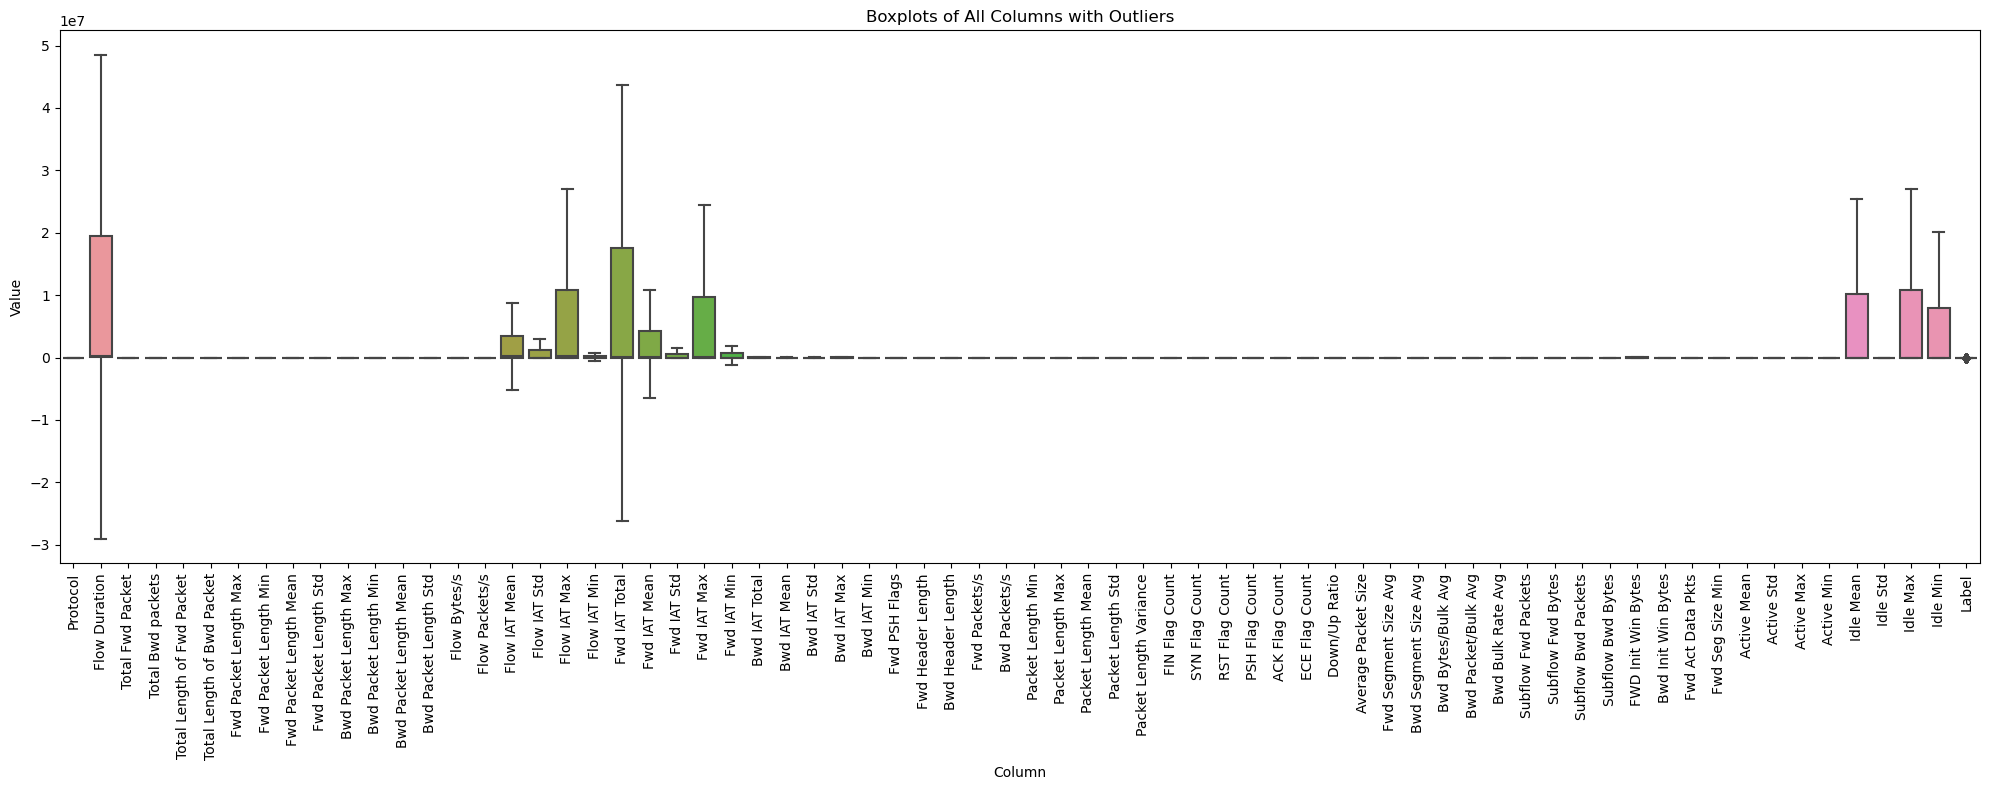

In [21]:
import seaborn as sns
import matplotlib.pyplot as plt
import pandas as pd

# Convert wide df (55 columns) into long format
df_melted = df2.melt(var_name="Column", value_name="Value")

plt.figure(figsize=(20, 8))  # wider figure to fit all columns on x-axis
sns.boxplot(x="Column", y="Value", data=df_melted)

plt.xticks(rotation=90)  # rotate labels for readability
plt.title("Boxplots of All Columns with Outliers")
plt.tight_layout()
plt.savefig("Graphs/outliers-removed.pdf")   # <-- save as PDF
plt.show()

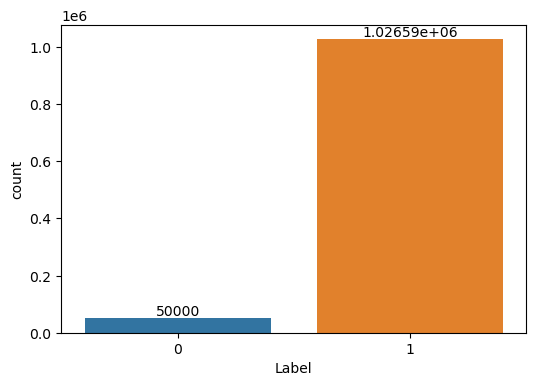

In [22]:
plt.figure(figsize=(6,4))
ax = sns.countplot(x='Label',data=df2)
for i in ax.containers:
    ax.bar_label(i,)

In [23]:
df2.shape

(1076588, 70)

In [24]:
df2.columns

Index(['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
      

In [25]:
columns = ['Protocol', 'Flow Duration', 'Total Fwd Packet', 'Total Bwd packets', 'Total Length of Fwd Packet', 'Total Length of Bwd Packet', 'Fwd Packet Length Max', 'Fwd Packet Length Min', 'Fwd Packet Length Mean', 'Fwd Packet Length Std', 'Bwd Packet Length Max', 'Bwd Packet Length Min', 'Bwd Packet Length Mean', 'Bwd Packet Length Std', 'Flow Bytes/s', 'Flow Packets/s', 'Flow IAT Mean', 'Flow IAT Std', 'Flow IAT Max', 'Flow IAT Min', 'Fwd IAT Total', 'Fwd IAT Mean', 'Fwd IAT Std', 'Fwd IAT Max', 'Fwd IAT Min', 'Bwd IAT Total', 'Bwd IAT Mean', 'Bwd IAT Std', 'Bwd IAT Max', 'Bwd IAT Min', 'Fwd PSH Flags', 'Fwd Header Length', 'Bwd Header Length', 'Fwd Packets/s', 'Bwd Packets/s', 'Packet Length Min', 'Packet Length Max', 'Packet Length Mean', 'Packet Length Std', 'Packet Length Variance', 'FIN Flag Count', 'SYN Flag Count', 'RST Flag Count', 'PSH Flag Count', 'ACK Flag Count', 'ECE Flag Count', 'Down/Up Ratio', 'Average Packet Size', 'Fwd Segment Size Avg', 'Bwd Segment Size Avg',
       'Bwd Bytes/Bulk Avg', 'Bwd Packet/Bulk Avg', 'Bwd Bulk Rate Avg', 'Subflow Fwd Packets', 'Subflow Fwd Bytes', 'Subflow Bwd Packets', 'Subflow Bwd Bytes', 'FWD Init Win Bytes', 'Bwd Init Win Bytes', 'Fwd Act Data Pkts', 'Fwd Seg Size Min', 'Active Mean', 'Active Std', 'Active Max', 'Active Min', 'Idle Mean', 'Idle Std', 'Idle Max', 'Idle Min']

In [29]:
!pip install --upgrade scikit-learn
!pip install --upgrade imbalanced-learn

Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB ? eta -:--:--
   ---------------------------------------- 0.0/8.9 MB 217.9 kB/s eta 0:00:41
   ---------------------------------------- 0.1/8.9 MB 656.4 kB/s eta 0:00:14
   - -------------------------------------- 0.2/8.9 MB 1.5 MB/s eta 0:00:06
   - -------------------------------------- 0.4/8.9 MB 2.0 MB/s eta 0:00:05
   --- ------------------------------------ 0.7/8.9 MB 3.1 MB/s eta 0:00:03
   ----- ---------------------------------- 1.3/8.9 MB 4.6 MB/s eta 0:00:02
   -------- ------------------------------- 1.8/8.9 MB 5.6 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.3/8.9 MB 6.4 MB/s eta 0:00:02
   ---------- ----------------------------- 2.4/8.9 MB 5.2 MB/s eta 0:00:02
   -------------- --

  You can safely remove it manually.


Defaulting to user installation because normal site-packages is not writeable
   ---------------------------------------- 0.0/240.0 kB ? eta -:--:--
   - -------------------------------------- 10.2/240.0 kB ? eta -:--:--
   ---- ---------------------------------- 30.7/240.0 kB 262.6 kB/s eta 0:00:01
   --------- ----------------------------- 61.4/240.0 kB 465.5 kB/s eta 0:00:01
   ---------------------------------- ----- 204.8/240.0 kB 1.1 MB/s eta 0:00:01
   ---------------------------------------- 240.0/240.0 kB 1.2 MB/s eta 0:00:00


In [30]:
from imblearn.over_sampling import SMOTE
from sklearn.model_selection import train_test_split

# Split features/labels
X = df2.drop(columns=['Label'])
y = df2['Label']

# Train-test split first (important to avoid leakage!)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

# Apply SMOTE on training set only
smote = SMOTE(random_state=42)
X_train_bal, y_train_bal = smote.fit_resample(X_train, y_train)

print(y_train.value_counts())
print(y_train_bal.value_counts())

Label
1    821270
0     40000
Name: count, dtype: int64
Label
1    821270
0    821270
Name: count, dtype: int64


<h2>ML Models</h2>

In [31]:
pip install xgboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [33]:
pip install lightgbm

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.


In [34]:
pip install catboost

Defaulting to user installation because normal site-packages is not writeable
Note: you may need to restart the kernel to use updated packages.



🔹 Training Logistic Regression...
Logistic Regression Performance:
  Accuracy:  0.9866
  Precision: 0.9864
  Recall:    0.9866
  F1-score:  0.9856

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.73      0.83     10000
           1       0.99      1.00      0.99    205318

    accuracy                           0.99    215318
   macro avg       0.98      0.86      0.91    215318
weighted avg       0.99      0.99      0.99    215318



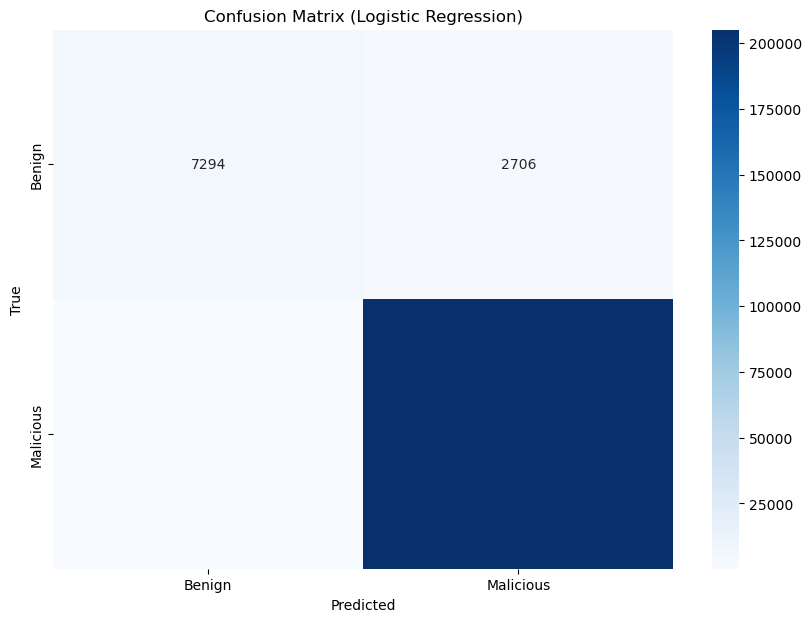


🔹 Training Random Forest...
Random Forest Performance:
  Accuracy:  0.9927
  Precision: 0.9926
  Recall:    0.9927
  F1-score:  0.9925

Classification Report:
               precision    recall  f1-score   support

           0       0.98      0.86      0.92     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.98      0.93      0.96    215318
weighted avg       0.99      0.99      0.99    215318



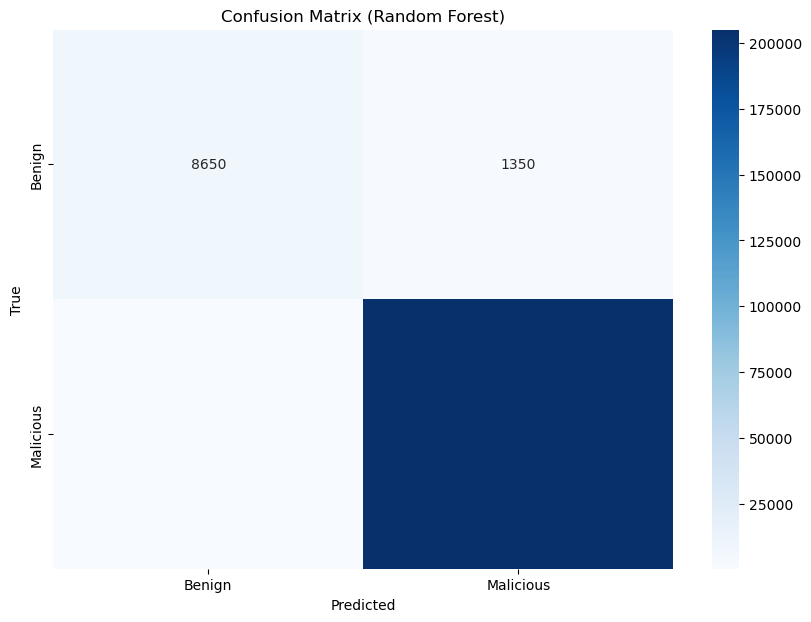


🔹 Training XGBoost...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [09:22:04] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


XGBoost Performance:
  Accuracy:  0.9928
  Precision: 0.9927
  Recall:    0.9928
  F1-score:  0.9925

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.86      0.92     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.99      0.93      0.96    215318
weighted avg       0.99      0.99      0.99    215318



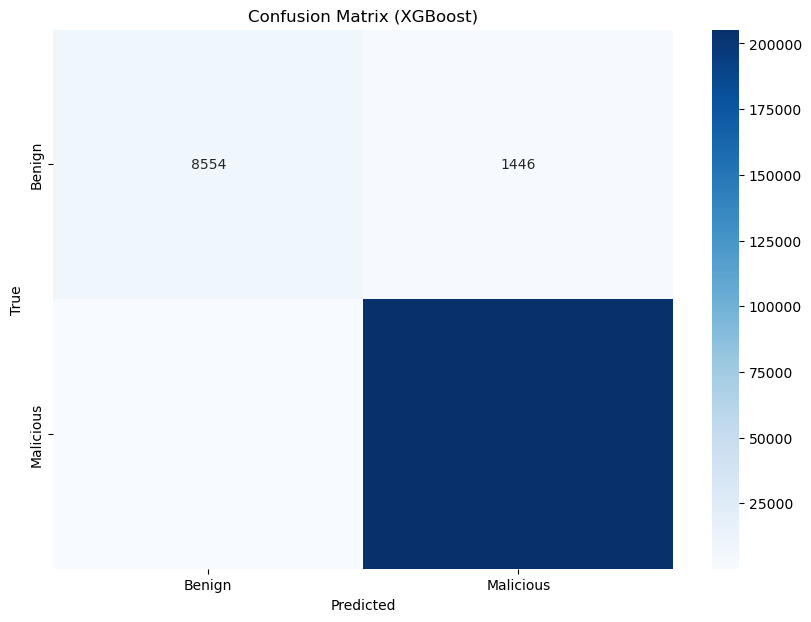


🔹 Training KNN...
KNN Performance:
  Accuracy:  0.9922
  Precision: 0.9920
  Recall:    0.9922
  F1-score:  0.9919

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.86      0.91     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.98      0.93      0.95    215318
weighted avg       0.99      0.99      0.99    215318



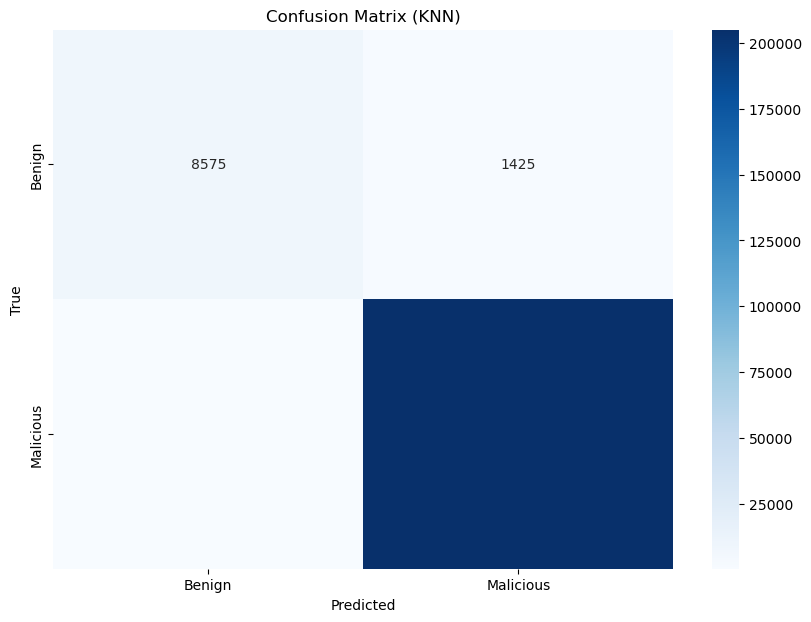


🔹 Training Naive Bayes...
Naive Bayes Performance:
  Accuracy:  0.7673
  Precision: 0.9552
  Recall:    0.7673
  F1-score:  0.8341

Classification Report:
               precision    recall  f1-score   support

           0       0.16      0.91      0.27     10000
           1       0.99      0.76      0.86    205318

    accuracy                           0.77    215318
   macro avg       0.58      0.83      0.56    215318
weighted avg       0.96      0.77      0.83    215318



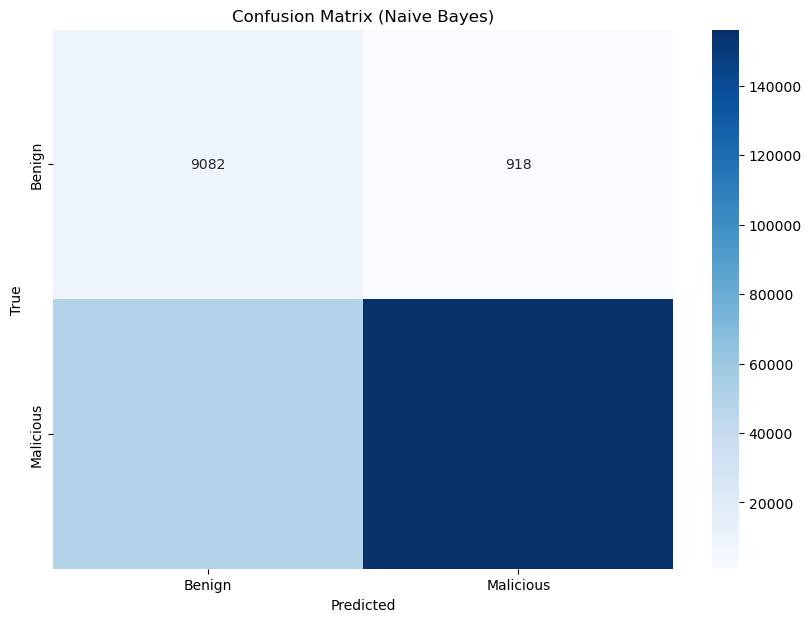


🔹 Training Decision Tree...
Decision Tree Performance:
  Accuracy:  0.9922
  Precision: 0.9921
  Recall:    0.9922
  F1-score:  0.9920

Classification Report:
               precision    recall  f1-score   support

           0       0.97      0.85      0.91     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.98      0.93      0.95    215318
weighted avg       0.99      0.99      0.99    215318



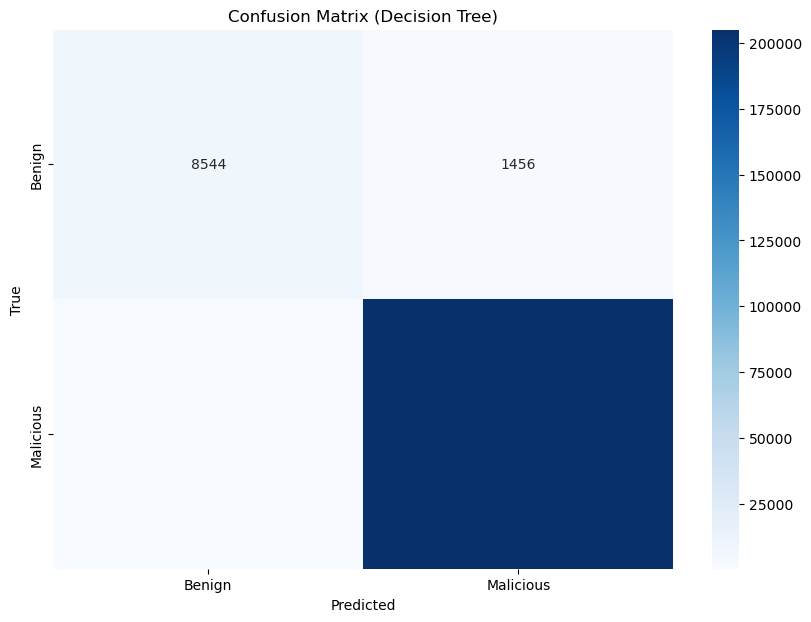


🔹 Training Gradient Boosting...
Gradient Boosting Performance:
  Accuracy:  0.9922
  Precision: 0.9922
  Recall:    0.9922
  F1-score:  0.9918

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.84      0.91     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.99      0.92      0.95    215318
weighted avg       0.99      0.99      0.99    215318



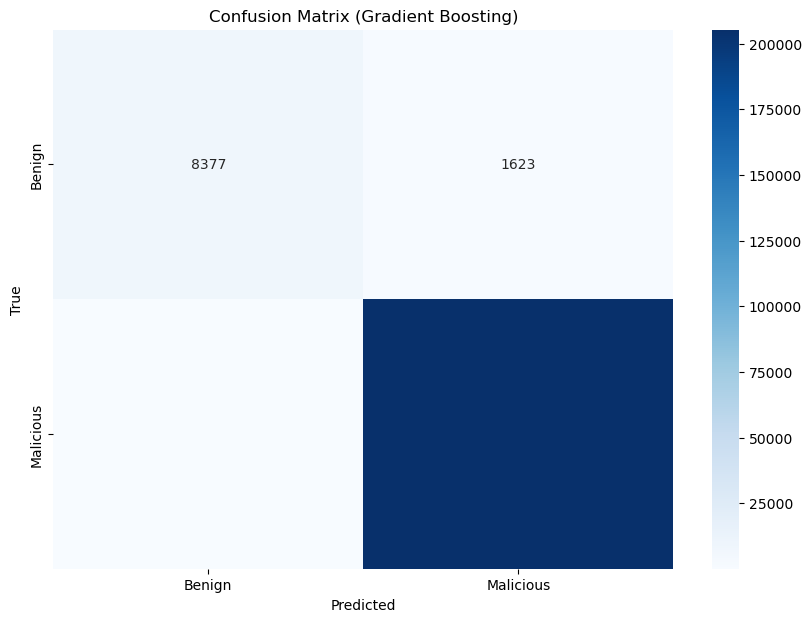


🔹 Training AdaBoost...
AdaBoost Performance:
  Accuracy:  0.9864
  Precision: 0.9866
  Recall:    0.9864
  F1-score:  0.9853

Classification Report:
               precision    recall  f1-score   support

           0       1.00      0.71      0.83     10000
           1       0.99      1.00      0.99    205318

    accuracy                           0.99    215318
   macro avg       0.99      0.85      0.91    215318
weighted avg       0.99      0.99      0.99    215318



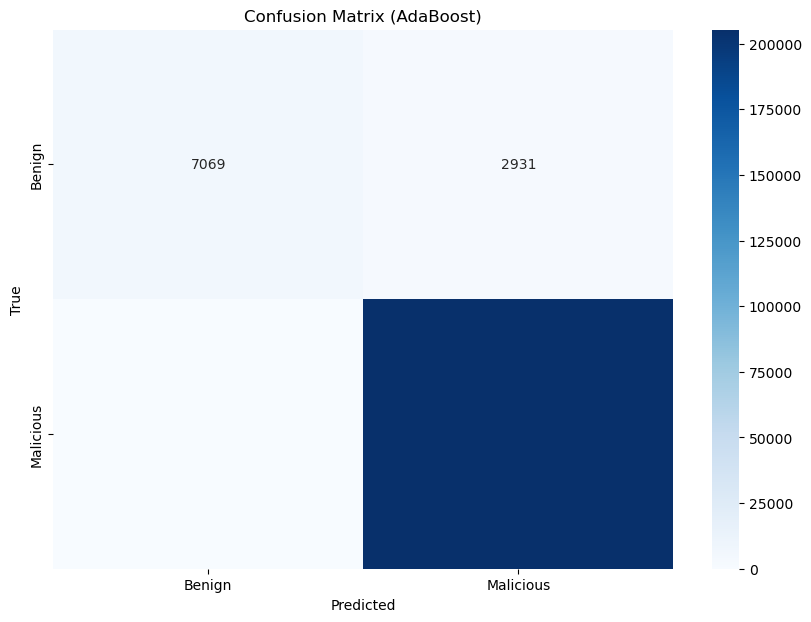


🔹 Training Extra Trees...
Extra Trees Performance:
  Accuracy:  0.9923
  Precision: 0.9921
  Recall:    0.9923
  F1-score:  0.9921

Classification Report:
               precision    recall  f1-score   support

           0       0.96      0.87      0.91     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.98      0.93      0.95    215318
weighted avg       0.99      0.99      0.99    215318



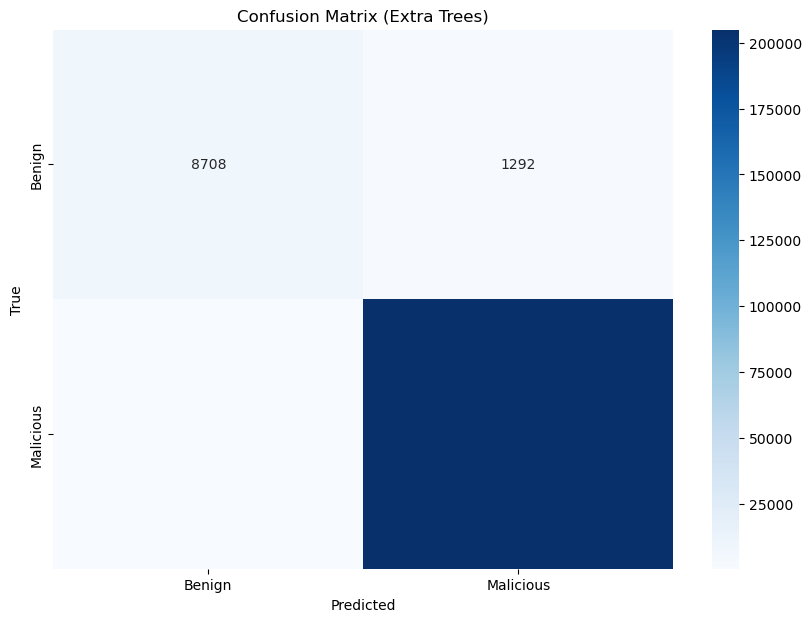


🔹 Training LightGBM...
LightGBM Performance:
  Accuracy:  0.9927
  Precision: 0.9927
  Recall:    0.9927
  F1-score:  0.9925

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.85      0.92     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.99      0.93      0.96    215318
weighted avg       0.99      0.99      0.99    215318



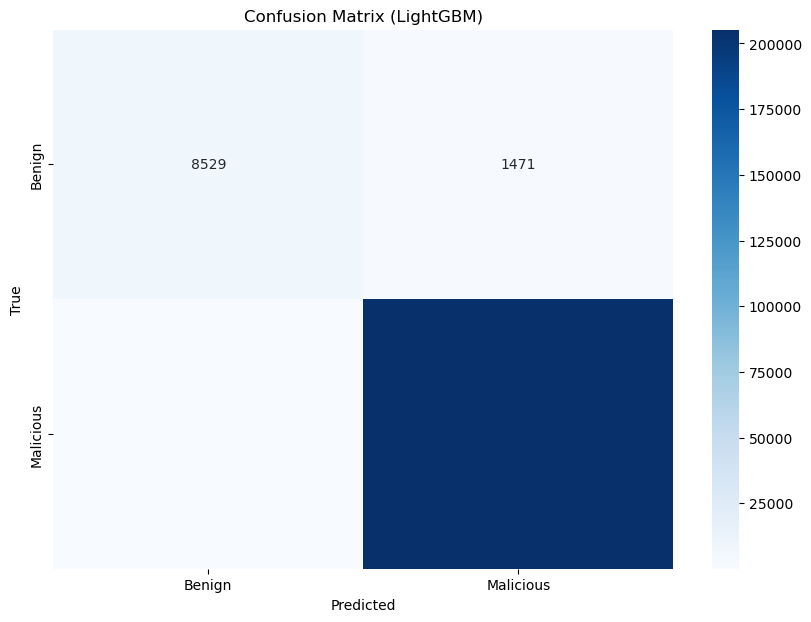


🔹 Training CatBoost...
CatBoost Performance:
  Accuracy:  0.9925
  Precision: 0.9925
  Recall:    0.9925
  F1-score:  0.9922

Classification Report:
               precision    recall  f1-score   support

           0       0.99      0.85      0.91     10000
           1       0.99      1.00      1.00    205318

    accuracy                           0.99    215318
   macro avg       0.99      0.92      0.95    215318
weighted avg       0.99      0.99      0.99    215318



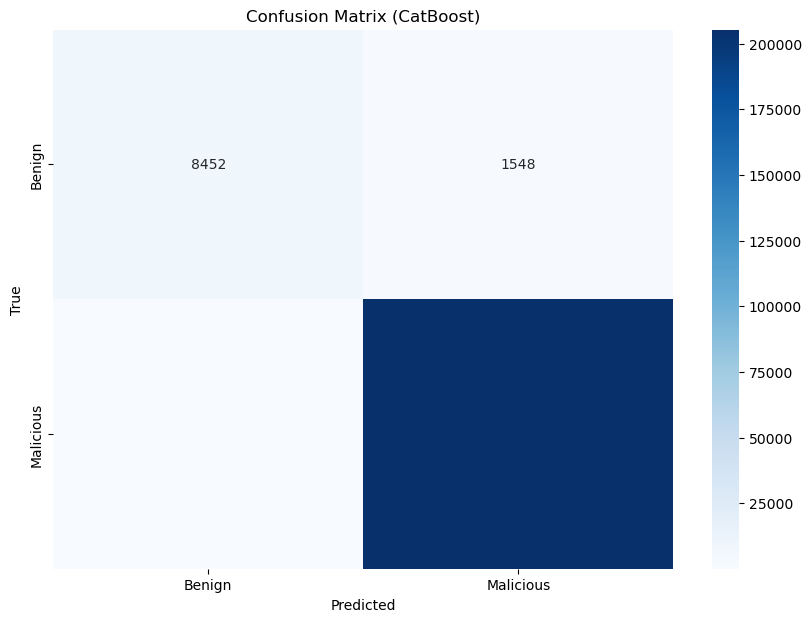


📊 Final Comparison:
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.986564   0.986424  0.986564  0.985637
Random Forest        0.992736   0.992643  0.992736  0.992528
XGBoost              0.992783   0.992749  0.992783  0.992536
KNN                  0.992170   0.992047  0.992170  0.991939
Naive Bayes          0.767335   0.955223  0.767335  0.834090
Decision Tree        0.992216   0.992113  0.992216  0.991971
Gradient Boosting    0.992165   0.992167  0.992165  0.991849
AdaBoost             0.986388   0.986579  0.986388  0.985267
Extra Trees          0.992253   0.992104  0.992253  0.992076
LightGBM             0.992718   0.992691  0.992718  0.992461
CatBoost             0.992481   0.992475  0.992481  0.992195


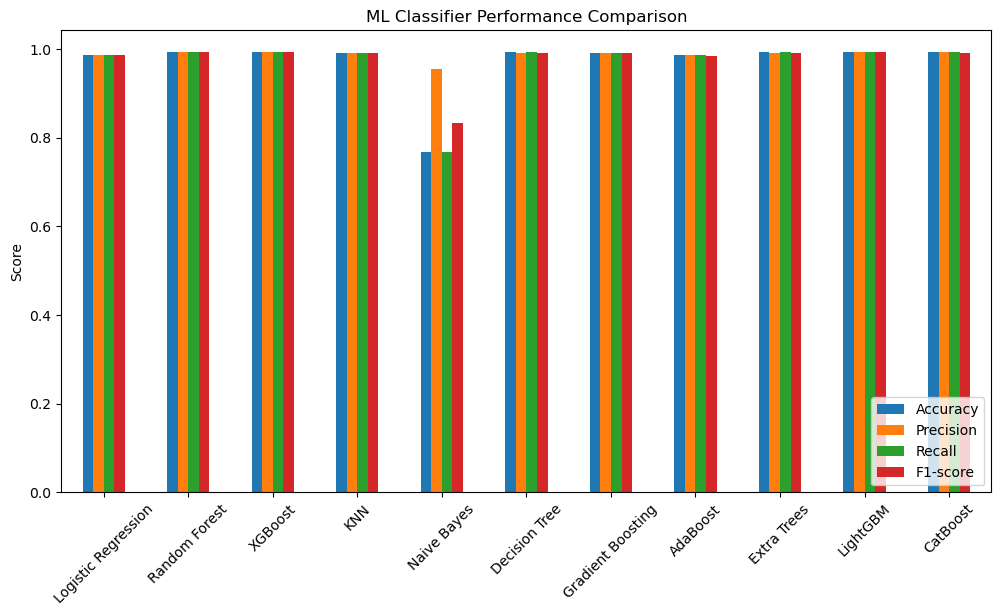

In [44]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier


# Encode labels
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# Train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y_encoded, test_size=0.2, random_state=42, stratify=y_encoded
)

# Feature scaling (important for SVM, KNN, LR)
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# =====================================
# Define Models
# =====================================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}

# =====================================
# Train & Evaluate
# =====================================
for name, model in models.items():
    print(f"\n🔹 Training {name}...")
    model.fit(X_train, y_train)
    y_pred = model.predict(X_test)

    acc = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, average="weighted", zero_division=0)
    rec = recall_score(y_test, y_pred, average="weighted", zero_division=0)
    f1 = f1_score(y_test, y_pred, average="weighted", zero_division=0)

    results[name] = {"Accuracy": acc, "Precision": prec, "Recall": rec, "F1-score": f1}

    print(f"{name} Performance:")
    print(f"  Accuracy:  {acc:.4f}")
    print(f"  Precision: {prec:.4f}")
    print(f"  Recall:    {rec:.4f}")
    print(f"  F1-score:  {f1:.4f}")
    print("\nClassification Report:\n", classification_report(y_test, y_pred, target_names=encoder.classes_.astype(str)))

    # Confusion Matrix
    class_names = ['Benign', 'Malicious']

    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(10,7))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                xticklabels=class_names,
                yticklabels=class_names)
    plt.title(f"Confusion Matrix ({name})")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.savefig(f"Graphs/Binary-ml-{name}.pdf")   # <-- save as PDF
    plt.show()

# =====================================
# Compare Results
# =====================================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison:\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("Graphs/Binary-ml-compare.pdf")   # <-- save as PDF
plt.show()


<h3>with k5-fold cross validation</h3>


🔹 Training Logistic Regression with 5-Fold Cross Validation...
Logistic Regression Avg Performance:
  Accuracy:  0.9865
  Precision: 0.9863
  Recall:    0.9865
  F1-score:  0.9855

🔹 Training Random Forest with 5-Fold Cross Validation...
Random Forest Avg Performance:
  Accuracy:  0.9926
  Precision: 0.9925
  Recall:    0.9926
  F1-score:  0.9924

🔹 Training XGBoost with 5-Fold Cross Validation...


C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:09:22] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:09:34] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:09:46] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:738: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\xgboost\training.py:183: UserWarning: [19:10:02] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:7

XGBoost Avg Performance:
  Accuracy:  0.9927
  Precision: 0.9926
  Recall:    0.9927
  F1-score:  0.9924

🔹 Training KNN with 5-Fold Cross Validation...
KNN Avg Performance:
  Accuracy:  0.9923
  Precision: 0.9921
  Recall:    0.9923
  F1-score:  0.9920

🔹 Training Naive Bayes with 5-Fold Cross Validation...
Naive Bayes Avg Performance:
  Accuracy:  0.7682
  Precision: 0.9552
  Recall:    0.7682
  F1-score:  0.8347

🔹 Training Decision Tree with 5-Fold Cross Validation...
Decision Tree Avg Performance:
  Accuracy:  0.9921
  Precision: 0.9920
  Recall:    0.9921
  F1-score:  0.9918

🔹 Training Gradient Boosting with 5-Fold Cross Validation...
Gradient Boosting Avg Performance:
  Accuracy:  0.9922
  Precision: 0.9922
  Recall:    0.9922
  F1-score:  0.9919

🔹 Training AdaBoost with 5-Fold Cross Validation...
AdaBoost Avg Performance:
  Accuracy:  0.9802
  Precision: 0.9806
  Recall:    0.9802
  F1-score:  0.9776

🔹 Training Extra Trees with 5-Fold Cross Validation...
Extra Trees Avg Perf

C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMClassifier was fitted with feature names
  warnings.warn(
C:\Users\Z840\AppData\Roaming\Python\Python311\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LGBMCla

LightGBM Avg Performance:
  Accuracy:  0.9927
  Precision: 0.9926
  Recall:    0.9927
  F1-score:  0.9924

🔹 Training CatBoost with 5-Fold Cross Validation...
CatBoost Avg Performance:
  Accuracy:  0.9925
  Precision: 0.9924
  Recall:    0.9925
  F1-score:  0.9922

📊 Final Comparison (5-Fold CV):
                      Accuracy  Precision    Recall  F1-score
Logistic Regression  0.986460   0.986315  0.986460  0.985519
Random Forest        0.992608   0.992499  0.992608  0.992405
XGBoost              0.992667   0.992628  0.992667  0.992413
KNN                  0.992258   0.992133  0.992258  0.992039
Naive Bayes          0.768192   0.955236  0.768192  0.834674
Decision Tree        0.992087   0.991971  0.992087  0.991845
Gradient Boosting    0.992244   0.992226  0.992244  0.991945
AdaBoost             0.980194   0.980597  0.980194  0.977612
Extra Trees          0.992137   0.991982  0.992137  0.991959
LightGBM             0.992656   0.992610  0.992656  0.992406
CatBoost             0.992453 

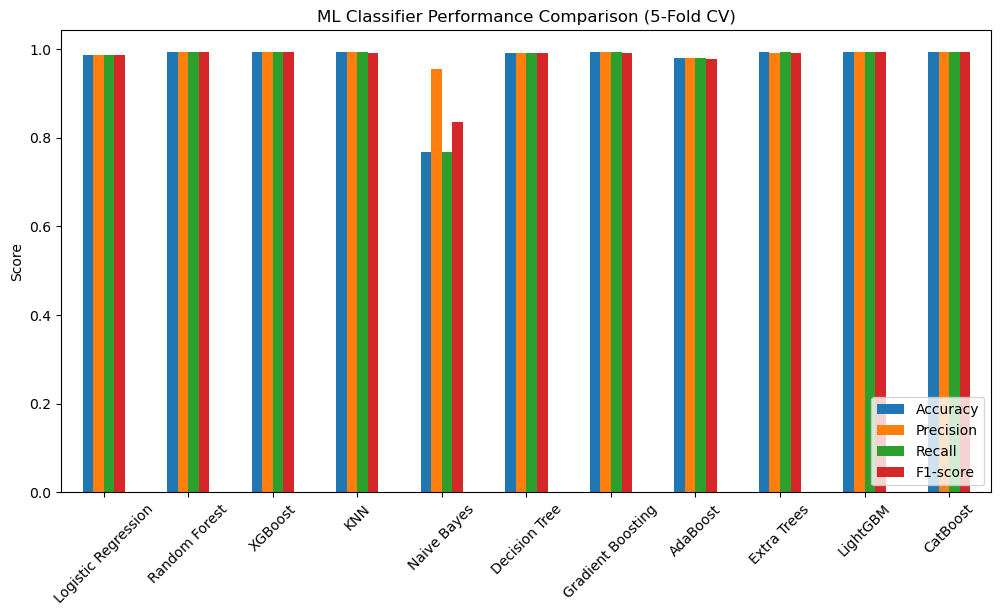

In [36]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import StratifiedKFold
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, classification_report, confusion_matrix

# ML Classifiers
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.naive_bayes import GaussianNB
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingClassifier, AdaBoostClassifier, ExtraTreesClassifier
from lightgbm import LGBMClassifier
from catboost import CatBoostClassifier

# =============================
# Encode labels
# =============================
encoder = LabelEncoder()
y_encoded = encoder.fit_transform(y)

# =============================
# Define Models
# =============================
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000, random_state=42),
    "Random Forest": RandomForestClassifier(n_estimators=200, random_state=42),
    "XGBoost": XGBClassifier(n_estimators=200, learning_rate=0.1, max_depth=6, 
                             use_label_encoder=False, eval_metric="mlogloss", random_state=42),
    "KNN": KNeighborsClassifier(n_neighbors=7),
    "Naive Bayes": GaussianNB(),
    "Decision Tree": DecisionTreeClassifier(random_state=42, max_depth=10),
    "Gradient Boosting": GradientBoostingClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "AdaBoost": AdaBoostClassifier(n_estimators=200, learning_rate=0.1, random_state=42),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, random_state=42),
    "LightGBM": LGBMClassifier(n_estimators=200, learning_rate=0.1, max_depth=-1, random_state=42, verbose=-1),
    "CatBoost": CatBoostClassifier(iterations=200, learning_rate=0.1, depth=6, verbose=0, random_state=42)
}

results = {}
kf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

# =============================
# Train & Cross-Validate
# =============================
for name, model in models.items():
    print(f"\n🔹 Training {name} with 5-Fold Cross Validation...")

    acc_scores, prec_scores, rec_scores, f1_scores = [], [], [], []

    fold = 1
    for train_idx, test_idx in kf.split(X, y_encoded):
        # Use iloc to index rows correctly
        X_train, X_test = X.iloc[train_idx], X.iloc[test_idx]
        y_train, y_test = y_encoded[train_idx], y_encoded[test_idx]

        # Feature scaling
        scaler = StandardScaler()
        X_train = scaler.fit_transform(X_train)
        X_test = scaler.transform(X_test)

        # Train & predict
        model.fit(X_train, y_train)
        y_pred = model.predict(X_test)


        # Metrics
        acc_scores.append(accuracy_score(y_test, y_pred))
        prec_scores.append(precision_score(y_test, y_pred, average="weighted", zero_division=0))
        rec_scores.append(recall_score(y_test, y_pred, average="weighted", zero_division=0))
        f1_scores.append(f1_score(y_test, y_pred, average="weighted", zero_division=0))

        # Save one confusion matrix per fold (optional)
        cm = confusion_matrix(y_test, y_pred)
        plt.figure(figsize=(6,5))
        sns.heatmap(cm, annot=True, fmt="d", cmap="Blues",
                    xticklabels=encoder.classes_,
                    yticklabels=encoder.classes_)
        plt.title(f"{name} - Confusion Matrix (Fold {fold})")
        plt.xlabel("Predicted")
        plt.ylabel("True")
        plt.savefig(f"Graphs/Binary-ml-{name}-fold{fold}.pdf")
        plt.close()
        fold += 1

    # Average results
    results[name] = {
        "Accuracy": np.mean(acc_scores),
        "Precision": np.mean(prec_scores),
        "Recall": np.mean(rec_scores),
        "F1-score": np.mean(f1_scores)
    }

    print(f"{name} Avg Performance:")
    print(f"  Accuracy:  {np.mean(acc_scores):.4f}")
    print(f"  Precision: {np.mean(prec_scores):.4f}")
    print(f"  Recall:    {np.mean(rec_scores):.4f}")
    print(f"  F1-score:  {np.mean(f1_scores):.4f}")

# =============================
# Compare Results
# =============================
results_df = pd.DataFrame(results).T
print("\n📊 Final Comparison (5-Fold CV):\n", results_df)

# Bar Plot Comparison
results_df.plot(kind="bar", figsize=(12,6))
plt.title("ML Classifier Performance Comparison (5-Fold CV)")
plt.ylabel("Score")
plt.xticks(rotation=45)
plt.legend(loc="lower right")
plt.savefig("Graphs/Binary-ml-compare-5fold.pdf")
plt.show()
